# Линейная и логистическая регрессия

Практический учебник по двум главным моделям для табличных данных. Цель — понимать формулы, видеть, что подбирает обучение, уверенно пользоваться sklearn и не путаться в параметрах.

В уроке нет случайного леса и нет отвлекающих шпаргалок по NumPy или matplotlib. Графики здесь нужны только для понимания регрессии, вероятности и регуляризации.

## Карта урока

1. Линейная регрессия: прогноз числа, MSE, веса и градиентный спуск.
2. Регуляризация: почему большие веса опасны, Ridge и Lasso, допустимая зона весов.
3. Логистическая регрессия: вероятность, сигмоида, log loss и порог.
4. Параметры sklearn: что действительно нужно знать.
5. Titanic: короткий честный эксперимент.
6. Практика: 10 задач с тестами.

Обозначения: X — таблица признаков, y — правильные ответы, w — веса признаков, b — свободный член, y с крышкой — прогноз.

In [34]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, Ridge, Lasso, LogisticRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score, accuracy_score, precision_score, recall_score, f1_score, log_loss, ConfusionMatrixDisplay

RANDOM_STATE = 42
plt.style.use('seaborn-v0_8-whitegrid')

# 1. Что такое модель и обучение

Модель получает признаки X и выдаёт прогноз. Обучение — подбор параметров модели по строкам, где правильный ответ y уже известен.

Пример: для квартиры признаками могут быть площадь и число комнат, а y — цена. Для Titanic признаками будут класс билета, возраст, цена и пол, а y — выжил или нет.

Важно различать две задачи:

- регрессия: нужно предсказать число, например цену;
- классификация: нужно выбрать класс, например 0 или 1.

Линейная регрессия решает первую задачу. Логистическая регрессия — вторую, хотя в названии есть слово регрессия.

# 2. Линейная регрессия

## Формула

Для одного признака модель — прямая:

ŷ = w × x + b

w — наклон прямой. Если x увеличился на 1, прогноз меняется на w. b — сдвиг: прогноз при x = 0.

Для нескольких признаков формула такая:

ŷ = w₁x₁ + w₂x₂ + ... + wₚxₚ + b

У каждого признака свой вес. Положительный вес двигает прогноз вверх, отрицательный — вниз. Интерпретировать размеры весов можно только осторожно: признаки должны быть в сопоставимом масштабе.

## Как понять, хороша ли прямая

Для каждого объекта есть ошибка: ошибка = прогноз − правильный ответ.

Обычная функция потерь линейной регрессии — средняя квадратичная ошибка:

MSE = (1/n) × Σ(ŷᵢ − yᵢ)²

Квадрат делает две вещи: ошибки с разными знаками не сокращаются, а большой промах получает большой штраф. Обучение ищет такие w и b, при которых MSE минимальна.

b = 36.5
w = 11.2
MSE = 0.45


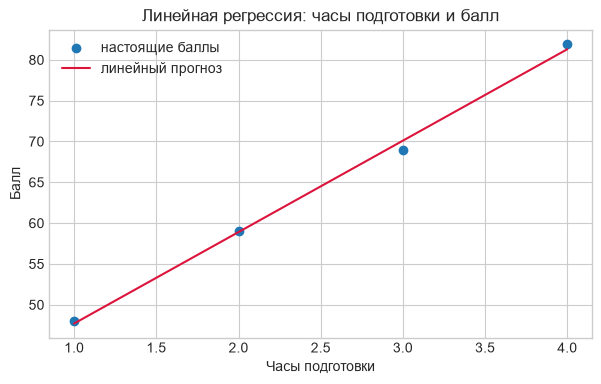

In [35]:
# Четыре наблюдения: часы подготовки и балл.
hours = np.array([[1.], [2.], [3.], [4.]])
scores = np.array([48., 59., 69., 82.])

linear_model = LinearRegression()
linear_model.fit(hours, scores)
prediction = linear_model.predict(hours)

print('b =', round(linear_model.intercept_, 2))
print('w =', round(linear_model.coef_[0], 2))
print('MSE =', round(mean_squared_error(scores, prediction), 2))

plt.figure(figsize=(7, 4))
plt.scatter(hours.ravel(), scores, label='настоящие баллы')
plt.plot(hours.ravel(), prediction, color='crimson', label='линейный прогноз')
plt.title('Линейная регрессия: часы подготовки и балл')
plt.xlabel('Часы подготовки')
plt.ylabel('Балл')
plt.legend()
plt.show()

## Как обучаются веса: идея градиентного спуска

Можно начать с w = 0 и b = 0. Затем:

1. посчитать прогноз и MSE;
2. определить, в какую сторону сдвинуть w и b, чтобы MSE уменьшилась;
3. сделать маленький шаг;
4. повторить.

Размер шага называют learning rate. В sklearn LinearRegression градиентный спуск вручную писать не нужно: библиотека решает задачу быстрее. Но понять идею важно: обучение не угадывает ответ, а систематически уменьшает функцию потерь.

После обучения: w = 2.0 b = 0.998


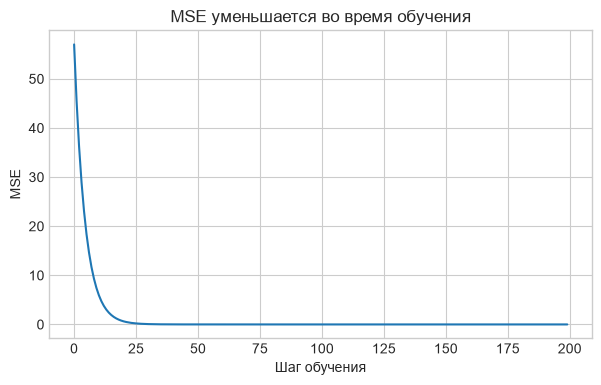

In [36]:
# Маленький градиентный спуск для прямой y = 2x + 1.
x = np.array([1., 2., 3., 4., 5.])
y = np.array([3., 5., 7., 9., 11.])

w = 0.0
b = 0.0
rate = 0.08
losses = []

for step in range(200):
    y_hat = w * x + b
    error = y_hat - y
    losses.append(np.mean(error ** 2))
    dw = 2 * np.mean(x * error)
    db = 2 * np.mean(error)
    w = w - rate * dw
    b = b - rate * db

print('После обучения: w =', round(w, 3), 'b =', round(b, 3))
plt.figure(figsize=(7, 4))
plt.plot(losses)
plt.title('MSE уменьшается во время обучения')
plt.xlabel('Шаг обучения')
plt.ylabel('MSE')
plt.show()

## LinearRegression в sklearn: необходимый минимум

| Что | Команда | Смысл |
|---|---|---|
| Создать модель | LinearRegression() | обычная линейная регрессия без регуляризации |
| Обучить | model.fit(X_train, y_train) | подобрать веса по train |
| Предсказать | model.predict(X_test) | получить числа |
| Веса | model.coef_ | по одному весу на признак |
| Сдвиг | model.intercept_ | значение b |
| Ошибка | mean_squared_error(y, pred) | меньше — лучше |
| fit_intercept=True | параметр модели | обычно оставляют включённым |
| positive=True | параметр модели | запретить отрицательные веса; нужно редко |

У LinearRegression почти нет настроек именно потому, что это базовая модель. Главное — правильно выбрать признаки и честно проверить качество на test.

# 3. Регуляризация: почему нельзя просто делать веса любыми

Если признаков много, в данных есть шум или признаки похожи друг на друга, модель может подобрать очень большие веса. Она хорошо объяснит train, но на новых данных будет нестабильной. Это переобучение.

Регуляризация добавляет штраф за большие веса. Модель теперь ищет компромисс: и ошибка должна быть маленькой, и веса не должны быть чрезмерными.

Свободный член b обычно не штрафуют: регуляризация действует на веса w.

## Ridge: L2-регуляризация

Ridge минимизирует:

MSE + α × (w₁² + w₂² + ... + wₚ²)

α — сила штрафа. При α = 0 получаем обычную линейную регрессию. Чем больше α, тем сильнее веса прижимаются к нулю, но обычно не становятся ровно нулевыми.

Эквивалентная геометрическая картинка: веса должны лежать внутри круга w₁² + w₂² ≤ R². Чем сильнее регуляризация, тем меньше допустимый круг.

/Users/mkir/.pyenv/versions/3.13.14/lib/python3.13/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 8322 (\N{SUBSCRIPT TWO}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)
/Users/mkir/.pyenv/versions/3.13.14/lib/python3.13/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 8321 (\N{SUBSCRIPT ONE}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


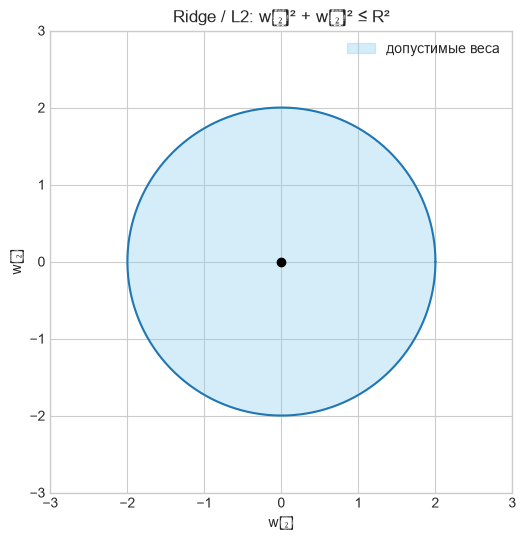

In [37]:
# L2: допустимая зона весов — круг.
angle = np.linspace(0, 2 * np.pi, 300)
radius = 2
circle_w1 = radius * np.cos(angle)
circle_w2 = radius * np.sin(angle)

plt.figure(figsize=(6, 6))
plt.fill(circle_w1, circle_w2, color='skyblue', alpha=.35, label='допустимые веса')
plt.plot(circle_w1, circle_w2, color='tab:blue')
plt.scatter([0], [0], color='black')
plt.title('Ridge / L2: w₁² + w₂² ≤ R²')
plt.xlabel('w₁')
plt.ylabel('w₂')
plt.xlim(-3, 3)
plt.ylim(-3, 3)
plt.gca().set_aspect('equal')
plt.legend()
plt.show()

## Lasso: L1-регуляризация

Lasso минимизирует:

MSE + α × (|w₁| + |w₂| + ... + |wₚ|)

У Lasso допустимая зона — ромб. У ромба углы лежат на осях, поэтому решение чаще попадает в угол: некоторые веса становятся ровно нулевыми. Это полезно, когда хочется автоматически отбросить слабые признаки.

Ridge чаще выбирают для устойчивых прогнозов. Lasso — когда важна разреженная модель и отбор признаков.

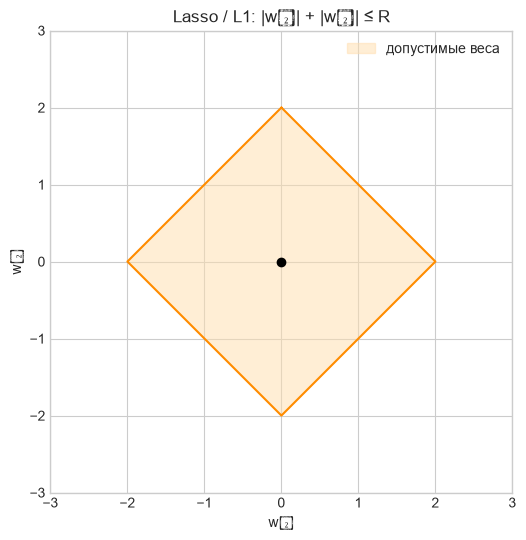

In [38]:
# L1: допустимая зона весов — ромб.
radius = 2
w1_diamond = [0, radius, 0, -radius, 0]
w2_diamond = [radius, 0, -radius, 0, radius]

plt.figure(figsize=(6, 6))
plt.fill(w1_diamond, w2_diamond, color='navajowhite', alpha=.5, label='допустимые веса')
plt.plot(w1_diamond, w2_diamond, color='darkorange')
plt.scatter([0], [0], color='black')
plt.title('Lasso / L1: |w₁| + |w₂| ≤ R')
plt.xlabel('w₁')
plt.ylabel('w₂')
plt.xlim(-3, 3)
plt.ylim(-3, 3)
plt.gca().set_aspect('equal')
plt.legend()
plt.show()

## Почему форма зоны важна

Представьте эллипсы одинаковой ошибки MSE вокруг лучшего решения. Обучение с регуляризацией ищет первый эллипс, который коснётся допустимой зоны весов.

Круг Ridge гладкий: касание редко оказывается строго на оси. Поэтому веса уменьшаются, но редко зануляются.

У ромба Lasso есть острые углы на осях: эллипс часто касается именно угла. В этот момент один из весов равен нулю. Это геометрическое объяснение отбора признаков Lasso.

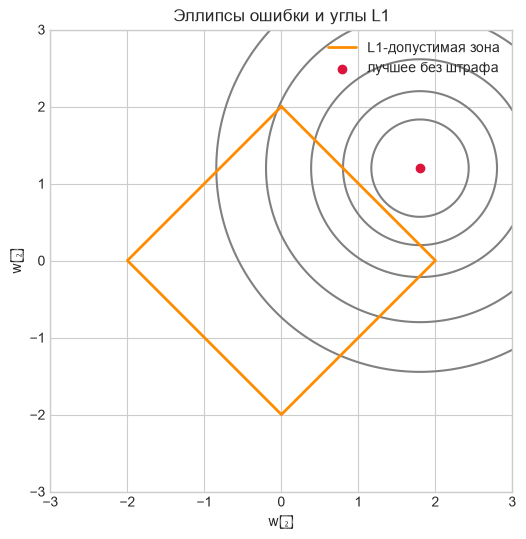

In [39]:
# Контуры одинаковой ошибки и L1-зона на одном простом графике.
w1, w2 = np.meshgrid(np.linspace(-3, 3, 200), np.linspace(-3, 3, 200))
loss_surface = (w1 - 1.8) ** 2 + (w2 - 1.2) ** 2

plt.figure(figsize=(6, 6))
plt.contour(w1, w2, loss_surface, levels=[0.4, 1, 2, 4, 7], colors='gray')
plt.plot(w1_diamond, w2_diamond, color='darkorange', linewidth=2, label='L1-допустимая зона')
plt.scatter([1.8], [1.2], color='crimson', label='лучшее без штрафа')
plt.title('Эллипсы ошибки и углы L1')
plt.xlabel('w₁')
plt.ylabel('w₂')
plt.xlim(-3, 3)
plt.ylim(-3, 3)
plt.gca().set_aspect('equal')
plt.legend()
plt.show()

## Ridge, Lasso и параметры sklearn

| Модель | Штраф | Главный параметр | Что происходит с весами |
|---|---|---|---|
| LinearRegression | нет | нет α | модель свободно подбирает веса |
| Ridge(alpha=...) | L2, сумма квадратов | alpha | веса становятся меньше |
| Lasso(alpha=...) | L1, сумма модулей | alpha | часть весов может стать нулём |
| ElasticNet | L1 + L2 | alpha, l1_ratio | компромисс Ridge и Lasso |

Для Ridge и Lasso α больше означает регуляризацию сильнее. Перед Ridge, Lasso и LogisticRegression числовые признаки надо стандартизировать, иначе штраф будет зависеть от единиц измерения.

In [40]:
# Один набор, три линейные модели: смотрим на веса.
X_small = np.array([[1., 1.], [2., 2.1], [3., 2.9], [4., 4.2], [5., 5.1]])
y_small = np.array([2., 4., 6., 8., 10.])

ordinary = LinearRegression().fit(X_small, y_small)
ridge = Ridge(alpha=2).fit(X_small, y_small)
lasso = Lasso(alpha=0.2).fit(X_small, y_small)

weights = pd.DataFrame({
    'LinearRegression': ordinary.coef_,
    'Ridge alpha=2': ridge.coef_,
    'Lasso alpha=0.2': lasso.coef_,
}, index=['w1', 'w2'])
print(weights.round(3))

    LinearRegression  Ridge alpha=2  Lasso alpha=0.2
w1               2.0          0.893            1.211
w2               0.0          0.901            0.669


# 4. Логистическая регрессия

Логистическая регрессия решает задачу классификации. Она не выдаёт просто 0 или 1: сначала оценивает вероятность класса 1.

Как и линейная модель, она считает линейный счёт:

z = w₁x₁ + ... + wₚxₚ + b

Но затем пропускает z через сигмоиду:

p = 1 / (1 + exp(−z))

Поэтому p всегда лежит между 0 и 1. При z = 0 вероятность равна 0.5. Большой положительный z даёт вероятность около 1, отрицательный — около 0.

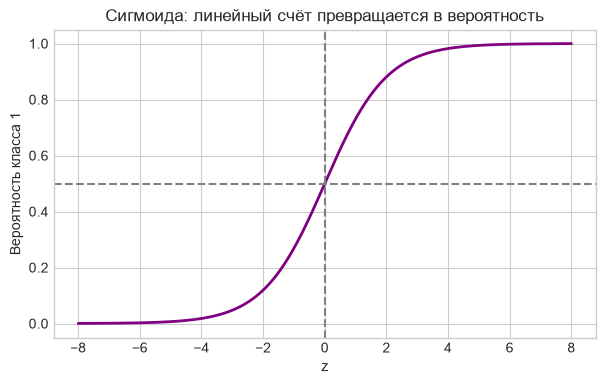

In [41]:
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

z_values = np.linspace(-8, 8, 300)
plt.figure(figsize=(7, 4))
plt.plot(z_values, sigmoid(z_values), color='purple', linewidth=2)
plt.axhline(0.5, color='gray', linestyle='--')
plt.axvline(0, color='gray', linestyle='--')
plt.title('Сигмоида: линейный счёт превращается в вероятность')
plt.xlabel('z')
plt.ylabel('Вероятность класса 1')
plt.ylim(-0.05, 1.05)
plt.show()

## Log loss и порог

Логистическая регрессия обучается не по accuracy. Она минимизирует log loss:

LogLoss = −(1/n) × Σ[yᵢ log(pᵢ) + (1 − yᵢ) log(1 − pᵢ)]

Если настоящий ответ 1, модель получает маленький штраф за p близкое к 1 и огромный штраф за p близкое к 0. Уверенная ошибка наказывается особенно сильно.

После получения вероятности выбирают порог. Обычно порог 0.5, но это не закон природы. Если опасно пропустить положительный объект, порог можно уменьшить; если ложная тревога дорога, увеличить.

In [42]:
y_true = np.array([0, 0, 1, 1])
p_careful = np.array([0.1, 0.4, 0.6, 0.9])
p_confident_wrong = np.array([0.01, 0.99, 0.99, 0.01])

print('Log loss осторожной модели:', round(log_loss(y_true, p_careful), 3))
print('Log loss уверенно ошибшейся модели:', round(log_loss(y_true, p_confident_wrong), 3))

probabilities = np.array([0.15, 0.48, 0.51, 0.88])
print('Порог 0.5:', (probabilities >= 0.5).astype(int))
print('Порог 0.8:', (probabilities >= 0.8).astype(int))

Log loss осторожной модели: 0.308
Log loss уверенно ошибшейся модели: 2.308
Порог 0.5: [0 0 1 1]
Порог 0.8: [0 0 0 1]


## Регуляризация в LogisticRegression

У логистической регрессии регуляризация тоже штрафует большие веса. Но sklearn использует параметр C, а не alpha:

C = 1 / α

Поэтому C маленькое означает сильную регуляризацию, а C большое — слабую. Это самая частая путаница.

Для LogisticRegression по умолчанию используется L2-регуляризация. L1 можно включить, но нужно выбрать совместимый solver.

## Главные параметры LogisticRegression в sklearn

| Параметр | Что выбрать сначала | Что означает |
|---|---|---|
| C=1.0 | начните с 1.0 | обратная сила регуляризации: меньше C — сильнее штраф |
| l1_ratio=0 | обычная L2-регуляризация | Ridge-подобная регуляризация |
| l1_ratio=1 | когда нужен отбор признаков | Lasso-подобная регуляризация |
| 0 < l1_ratio < 1 | смешать L1 и L2 | ElasticNet-подобная регуляризация |
| solver='lbfgs' | обычный L2 | хороший стандартный решатель |
| solver='saga' | l1_ratio больше нуля | нужен для L1 и смешанной регуляризации |
| solver='liblinear' | старые версии sklearn | встречается в старом синтаксисе L1/L2 |
| max_iter=1000 | безопасный учебный выбор | максимум шагов оптимизации |
| class_weight='balanced' | при сильном дисбалансе | увеличивает вес редкого класса |
| random_state=42 | для повторяемости | фиксирует случайность решателя |

В современных версиях sklearn настройка penalty устаревает. Для нового кода используйте l1_ratio: 0 для L2, 1 для L1. Если l1_ratio больше нуля, выбирайте solver='saga'.

# 5. Titanic: простой честный эксперимент

Мы предсказываем survived по pclass, age, fare и sex. Сначала делим данные на train и test. Затем всё, что вычисляется из данных, считаем только на train: медиану возраста, среднее и стандартное отклонение.

Здесь намеренно нет Pipeline: все шаги видны отдельно. В реальном проекте Pipeline помогает не забыть эти шаги, но сначала важно понимать механику.

In [43]:
df = pd.read_csv('titanic.csv')

X = df[['pclass', 'age', 'fare', 'sex']].copy()
y = df['survived'].copy()
X['sex'] = (X['sex'] == 'female').astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=RANDOM_STATE, stratify=y
)

age_median = X_train['age'].median()
X_train['age'] = X_train['age'].fillna(age_median)
X_test['age'] = X_test['age'].fillna(age_median)

mean = X_train.mean()
std = X_train.std(ddof=0)
X_train_scaled = (X_train - mean) / std
X_test_scaled = (X_test - mean) / std

print('Train:', X_train_scaled.shape, 'Test:', X_test_scaled.shape)
print('Доля выживших:', round(y.mean(), 3))

Train: (668, 4) Test: (223, 4)
Доля выживших: 0.384


In [44]:
# Базовая логистическая регрессия с L2-регуляризацией.
model = LogisticRegression(C=1.0, solver='lbfgs', max_iter=1000, random_state=RANDOM_STATE)
model.fit(X_train_scaled, y_train)

pred = model.predict(X_test_scaled)
proba = model.predict_proba(X_test_scaled)[:, 1]

print('Accuracy:', round(accuracy_score(y_test, pred), 3))
print('Log loss:', round(log_loss(y_test, proba), 3))
print('Веса:')
print(pd.Series(model.coef_[0], index=X.columns).round(3))

Accuracy: 0.771
Log loss: 0.49
Веса:
pclass   -0.940
age      -0.466
fare      0.096
sex       1.244
dtype: float64


Вероятность выживания: 0.084
Прогноз класса: 0
Правильный ответ: 0


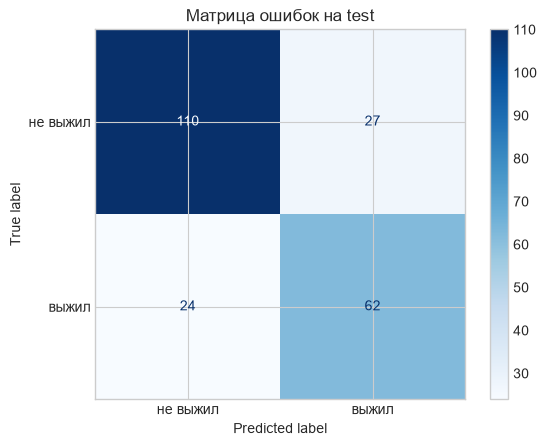

In [45]:
# Один пассажир из test: вероятность и решение модели.
one_passenger = X_test_scaled.iloc[[0]]
print('Вероятность выживания:', round(model.predict_proba(one_passenger)[0, 1], 3))
print('Прогноз класса:', int(model.predict(one_passenger)[0]))
print('Правильный ответ:', int(y_test.iloc[0]))

ConfusionMatrixDisplay.from_predictions(y_test, pred, display_labels=['не выжил', 'выжил'], cmap='Blues')
plt.title('Матрица ошибок на test')
plt.show()

## Как C меняет веса и качество

Ниже один простой эксперимент. Меняем только C и каждый раз обучаем одинаковую модель. Не подбирайте C по test в реальном соревновании: для выбора параметров нужна отдельная validation-выборка или кросс-валидация. Здесь test используется только как наглядный пример.

Смотрите на два факта: маленькое C сильнее сжимает веса, а качество не обязано монотонно расти при увеличении C.

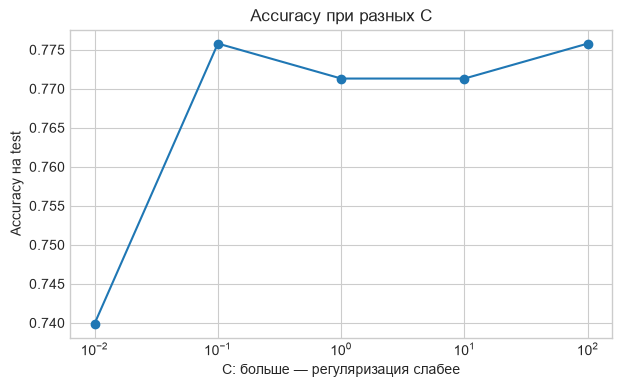

In [46]:
C_values = [0.01, 0.1, 1, 10, 100]
accuracies = []
weights_age = []
weights_fare = []

for C in C_values:
    current_model = LogisticRegression(C=C, max_iter=1000, random_state=RANDOM_STATE)
    current_model.fit(X_train_scaled, y_train)
    current_pred = current_model.predict(X_test_scaled)
    accuracies.append(accuracy_score(y_test, current_pred))
    weights_age.append(current_model.coef_[0][1])
    weights_fare.append(current_model.coef_[0][2])

plt.figure(figsize=(7, 4))
plt.plot(C_values, accuracies, marker='o')
plt.xscale('log')
plt.title('Accuracy при разных C')
plt.xlabel('C: больше — регуляризация слабее')
plt.ylabel('Accuracy на test')
plt.show()

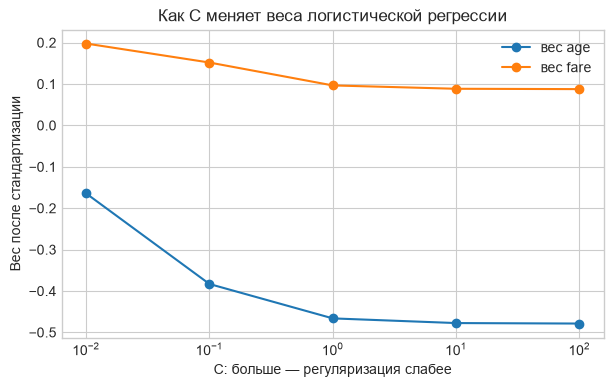

In [47]:
plt.figure(figsize=(7, 4))
plt.plot(C_values, weights_age, marker='o', label='вес age')
plt.plot(C_values, weights_fare, marker='o', label='вес fare')
plt.xscale('log')
plt.title('Как C меняет веса логистической регрессии')
plt.xlabel('C: больше — регуляризация слабее')
plt.ylabel('Вес после стандартизации')
plt.legend()
plt.show()

# 6. Две большие практические работы

Это главная практика урока. В каждой работе есть два файла: train содержит правильный ответ и нужен для обучения и проверки, test не содержит ответа и нужен только для финальных предсказаний. В каждом файле ровно 1000 строк.

В реальной задаче почти никогда не бывает таблицы, где достаточно написать model.fit(X, y). Сначала нужно понять, что означают признаки, убрать данные из будущего, исправить текстовые числа, заполнить пропуски и честно измерить качество. Обе работы специально содержат такие ловушки. Не используйте test для выбора признаков, настройки параметров или подсчёта качества: его ответы нам неизвестны.

## Маленькие функции для честной оценки

Loss показывает, насколько ошибается модель: чем меньше, тем лучше. Score показывает качество в понятной шкале. Для регрессии используем MSE, MAE и R²; для классификации — log loss, accuracy, precision, recall и F1. Функции ниже не обучают модель: они только оценивают уже сделанные предсказания на валидационной части train.

In [ ]:
def regression_report(y_true, y_pred):
    mse = mean_squared_error(y_true, y_pred)
    mae = mean_absolute_error(y_true, y_pred)
    r2 = r2_score(y_true, y_pred)
    print(f'MSE (loss): {mse:.2f}')
    print(f'MAE: {mae:.2f}')
    print(f'R² (score): {r2:.3f}')
    return {'mse': mse, 'mae': mae, 'r2': r2}


def classification_report_simple(y_true, probabilities, threshold=0.5):
    predicted = (np.array(probabilities) >= threshold).astype(int)
    loss = log_loss(y_true, probabilities)
    accuracy = accuracy_score(y_true, predicted)
    precision = precision_score(y_true, predicted, zero_division=0)
    recall = recall_score(y_true, predicted, zero_division=0)
    f1 = f1_score(y_true, predicted, zero_division=0)
    print(f'Log loss: {loss:.3f}')
    print(f'Accuracy: {accuracy:.3f}')
    print(f'Precision: {precision:.3f}')
    print(f'Recall: {recall:.3f}')
    print(f'F1 (score): {f1:.3f}')
    return {'log_loss': loss, 'accuracy': accuracy, 'precision': precision, 'recall': recall, 'f1': f1}

## Задача 1. Топливо для грузового рейса на Марсе — регрессия

Компания планирует грузовые рейсы между марсианскими станциями. Нужно предсказать расход топлива fuel_used_liters до вылета. Ошибка в несколько литров допустима, но систематически ошибаться нельзя. Постройте Ridge или Lasso и подготовьте файл task1_predictions.csv с колонками flight_id и fuel_used_liters.

Данные: task1_train.csv и task1_test.csv. Целевая колонка есть только в train: fuel_used_liters.

### Ловушки, которые нужно заметить

1. after_flight_fuel_estimate и logbook_status_after_landing появляются после посадки. Это утечка ответа из будущего: исключите их. С ними валидация будет подозрительно хорошей, но настоящая модель бесполезной.
2. flight_id уникален почти для каждой строки. Он не описывает рейс и помогает модели запомнить train. Уберите его из признаков, но сохраните для файла ответа.
3. distance_km и distance_miles_redundant — одна и та же информация в разных единицах. Оставьте только distance_km.
4. radio_temperature_text выглядит числом, но иногда в нём написано sensor_off. Превратите его в число через pd.to_numeric(..., errors='coerce'); затем заполните пропуск медианой, найденной только на обучающей части.
5. В числах и категориях есть пропуски. Заполняйте численные признаки медианой train, категориальные — строкой unknown.
6. sector, reactor_model и weather_code — категории. В test встретится weather_code = solar_glare, которого нет в train. Используйте pd.get_dummies и обязательно выровняйте столбцы train и test через reindex.
7. noise_sensor_1 ... noise_sensor_5 — чистый шум. Сравните модель с ними и без них; регуляризация должна помогать не доверять лишним весам.
8. Влияние пыли не совсем линейно. Попробуйте осмысленные признаки dust_level ** 2 или cargo_mass_kg * dust_level, но добавляйте их по одному и проверяйте на валидации.
9. В test другое соотношение секторов. Не считайте, что хорошая точность на одной случайной разбивке гарантирует победу; выбирайте простую устойчивую модель.
10. Встречаются выбросы. Посмотрите один график scatter, например cargo_mass_kg против fuel_used_liters, и не удаляйте строку только потому, что она кажется странной: сначала объясните, почему это ошибка измерения.

In [ ]:
train = pd.read_csv('task1_train.csv')
test = pd.read_csv('task1_test.csv')

print(train.shape, test.shape)
print(train[['fuel_used_liters', 'cargo_mass_kg', 'dust_level']].describe())
print(train.isna().sum().sort_values(ascending=False).head(10))

plt.figure(figsize=(8, 5))
plt.scatter(train['cargo_mass_kg'], train['fuel_used_liters'], alpha=0.45)
plt.xlabel('Масса груза, кг')
plt.ylabel('Расход топлива, л')
plt.show()

### План решения

1. Скопируйте flight_id из test в переменную ids.
2. Отделите y = train['fuel_used_liters']; удалите из X цель, ID, обе утечки и дублирующее расстояние. Из test удалите те же признаки, кроме цели — её там нет.
3. Преобразуйте radio_temperature_text. Добавьте не более двух осмысленных новых признаков.
4. Разделите X и y на обучение и валидацию: test_size=0.25, random_state=42. Все медианы и средние для стандартизации считайте только на обучении.
5. Закодируйте категории, выровняйте набор столбцов, стандартизируйте числа. Для Ridge особенно важно, чтобы признаки были в одном масштабе.
6. Переберите несколько значений alpha у Ridge, например 0.01, 0.1, 1, 10, 100. После каждого варианта вызовите regression_report(y_valid, prediction). Выберите alpha по валидации, а не по train.
7. Обучите выбранную модель на всём очищенном train, сделайте предсказания для test и сохраните их. В итоговом файле должно быть 1000 строк и ни одного пропуска.

In [ ]:
# Этот каркас запускается и оставляет места для вашего решения.
target = 'fuel_used_liters'
ids = test['flight_id'].copy()
drop_train = [target, 'flight_id', 'after_flight_fuel_estimate',
              'logbook_status_after_landing', 'distance_miles_redundant']
drop_test = ['flight_id', 'after_flight_fuel_estimate',
             'logbook_status_after_landing', 'distance_miles_redundant']

X = train.drop(columns=drop_train).copy()
X_final = test.drop(columns=drop_test).copy()
y = train[target].copy()

for table in [X, X_final]:
    table['radio_temperature_text'] = pd.to_numeric(
        table['radio_temperature_text'], errors='coerce'
    )

X_train, X_valid, y_train, y_valid = train_test_split(
    X, y, test_size=0.25, random_state=42
)
print(X_train.shape, X_valid.shape, X_final.shape)
# Дальше: заполнение пропусков, get_dummies, reindex, стандартизация, Ridge и regression_report.

## Задача 2. Подлинность артефакта со дна океана — классификация

Музей принимает артефакты, поднятые с океанского дна. Нужно до лабораторной экспертизы оценить вероятность того, что артефакт настоящий. Постройте LogisticRegression и подготовьте task2_predictions.csv с колонками artifact_id, is_authentic_probability и is_authentic.

Данные: task2_train.csv и task2_test.csv. Цель в train — is_authentic, где 1 означает подлинный артефакт.

### Ловушки, которые нужно заметить

1. lab_verdict_after_test — лабораторный вердикт после экспертизы. Это прямая утечка; не используйте его.
2. artifact_id уникален, а collector_code почти уникален. Они не помогут честному обобщению. Сохраните artifact_id только для итогового файла, оба признака удалите из X.
3. spectrometer_peak_text хранит числа как текст вида 1.73 keV, а иногда unreadable. Удалите суффикс ' keV', затем используйте pd.to_numeric(..., errors='coerce') и заполните медианой обучения.
4. Есть пропуски, категориальные признаки и разные категории в train и test: например, MAGNETO-Q есть только в test. После pd.get_dummies выравнивайте test по столбцам train.
5. Классы несбалансированы. Поэтому не доверяйте только accuracy: модель, всегда отвечающая «не настоящий», может выглядеть неплохо. Смотрите precision, recall, F1 и log loss.
6. В test другое распределение dive_region. Не подстраивайтесь под конкретные строки test и не используйте test при выборе C.
7. Данные разных масштабов: depth_m и signal_to_noise отличаются по величине. Перед регуляризованной логистической регрессией стандартизируйте числа по среднему и стандартному отклонению обучения.
8. Порог 0.5 — не закон природы. После обучения сравните, что происходит с precision и recall при порогах 0.35, 0.5 и 0.65. Решение о пороге зависит от цены ошибки: пропустить подлинник или ошибочно принять подделку.

In [ ]:
train = pd.read_csv('task2_train.csv')
test = pd.read_csv('task2_test.csv')

print(train.shape, test.shape)
print(train['is_authentic'].value_counts(normalize=True))
print(train.isna().sum().sort_values(ascending=False).head(10))

plt.figure(figsize=(8, 5))
plt.hist(train.loc[train['is_authentic'] == 0, 'resonance_hz'], bins=25, alpha=0.6, label='подделка')
plt.hist(train.loc[train['is_authentic'] == 1, 'resonance_hz'], bins=25, alpha=0.6, label='подлинник')
plt.xlabel('Резонанс, Гц')
plt.legend()
plt.show()

### План решения

1. Сохраните test['artifact_id'] в ids и отделите цель. Уберите artifact_id, collector_code и lab_verdict_after_test из признаков.
2. Превратите spectrometer_peak_text в число. Заполните пропуски и закодируйте material_guess, dive_region, scanner_model.
3. Разбейте train на обучение и валидацию с test_size=0.25, random_state=42 и stratify=y, чтобы доля классов сохранилась.
4. Стандартизируйте числовые признаки по X_train. Обучите LogisticRegression(max_iter=2000, C=...). Возьмите несколько C: 0.01, 0.1, 1, 10. Малый C означает более сильную регуляризацию.
5. Передайте вероятности класса 1 в classification_report_simple. Сравните пороги 0.35, 0.5 и 0.65.
6. После выбора C и порога обучите на всём очищенном train. В файле ответа probability — число от 0 до 1, а is_authentic — 0 или 1. Проверьте число строк и отсутствие NaN.

In [ ]:
# Каркас второй работы.
target = 'is_authentic'
ids = test['artifact_id'].copy()
drop_train = [target, 'artifact_id', 'collector_code', 'lab_verdict_after_test']
drop_test = ['artifact_id', 'collector_code', 'lab_verdict_after_test']

X = train.drop(columns=drop_train).copy()
X_final = test.drop(columns=drop_test).copy()
y = train[target].copy()

for table in [X, X_final]:
    text_number = table['spectrometer_peak_text'].str.replace(' keV', '', regex=False)
    table['spectrometer_peak_text'] = pd.to_numeric(text_number, errors='coerce')

X_train, X_valid, y_train, y_valid = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)
print(y_train.mean(), y_valid.mean())
# Дальше: заполнение, get_dummies, reindex, стандартизация, LogisticRegression и classification_report_simple.

### Финальная проверка перед сдачей

- В model.fit попали только признаки, доступные до события.
- Статистики заполнения и стандартизации получены из обучающей части, не из валидации или test.
- Все столбцы test совпадают со столбцами, на которых обучалась модель.
- Качество выбиралось по валидации, а не по train.
- Файл предсказаний содержит ровно 1000 строк; в нём нет NaN, лишнего индекса и целевой колонки из train.
- Если результат кажется невероятно хорошим, ещё раз ищите утечку.

## Архив: маленькие тренировки (необязательно)

Две работы выше — основная практика урока. Эти короткие задачи оставлены только для тех, кто хочет отдельно потренировать формулы и API sklearn. Они не обязательны для выполнения проектов.

Порядок задач: формула → sklearn-линейная модель → Ridge → сигмоида и log loss → стандартизация → LogisticRegression с L2 и L1.

In [48]:
from tests_ml_basics import *

### Задача 1. MSE

Напишите mse(y_true, y_pred): среднее квадратов разностей. Подсказка: np.mean((y_true - y_pred) ** 2).

Проверка: test_task1(mse).

In [49]:
def mse(y_true, y_pred):
    # ваш код
    pass

# test_task1(mse)

### Задача 2. Формула прямой

Напишите linear_predict(x, w, b), которая возвращает w * x + b как NumPy-массив.

Проверка: test_task2(linear_predict).

In [50]:
def linear_predict(x, w, b):
    # ваш код
    pass

# test_task2(linear_predict)

### Задача 3. LinearRegression

Напишите fit_linear(X, y): создайте LinearRegression, обучите через fit и верните модель.

Проверка: test_task3(fit_linear).

In [51]:
def fit_linear(X, y):
    # ваш код
    pass

# test_task3(fit_linear)

### Задача 4. Ridge

Напишите fit_ridge(X, y, alpha): создайте Ridge(alpha=alpha), обучите и верните модель. Что случится с регуляризацией, если alpha увеличить?

Проверка: test_task4(fit_ridge).

In [52]:
def fit_ridge(X, y, alpha):
    # ваш код
    pass

# test_task4(fit_ridge)

### Задача 5. Сигмоида

Напишите sigmoid(z) по формуле 1 / (1 + np.exp(-z)).

Проверка: test_task5(sigmoid).

In [53]:
def sigmoid(z):
    # ваш код
    pass

# test_task5(sigmoid)

### Задача 6. Порог вероятности

Напишите classify_probabilities(probabilities, threshold). Верните массив 0 и 1: 1 там, где вероятность не меньше threshold.

Проверка: test_task6(classify_probabilities).

In [54]:
def classify_probabilities(probabilities, threshold):
    # ваш код
    pass

# test_task6(classify_probabilities)

### Задача 7. Log loss

Напишите binary_log_loss(y_true, probabilities). Можно использовать sklearn.metrics.log_loss.

Проверка: test_task7(binary_log_loss).

In [55]:
def binary_log_loss(y_true, probabilities):
    # ваш код
    pass

# test_task7(binary_log_loss)

### Задача 8. Честная стандартизация

Напишите standardize_train_test(train, test). Посчитайте mean и std только из train, верните два новых DataFrame: train_scaled и test_scaled. Используйте std(ddof=0).

Проверка: test_task8(standardize_train_test).

In [56]:
def standardize_train_test(train, test):
    # ваш код
    pass

# test_task8(standardize_train_test)

### Задача 9. LogisticRegression с L2

Напишите fit_logistic(X, y, C). Создайте LogisticRegression с переданным C, max_iter=1000, обучите и верните. L2 можно не писать: это значение по умолчанию.

Проверка: test_task9(fit_logistic).

In [57]:
def fit_logistic(X, y, C):
    # ваш код
    pass

# test_task9(fit_logistic)

### Задача 10. LogisticRegression с L1

Напишите fit_l1_logistic(X, y, C). Используйте l1_ratio=1, solver='saga', max_iter=1000, обучите и верните модель. Почему L1 может занулить часть весов?

Проверка: test_task10(fit_l1_logistic).

In [58]:
def fit_l1_logistic(X, y, C):
    # ваш код
    pass

# test_task10(fit_l1_logistic)

# Итог перед олимпиадой

- Числовой прогноз: LinearRegression, качество через MSE.
- Классификация 0/1: LogisticRegression, смотрите probability, accuracy и log loss.
- Регуляризация защищает от больших нестабильных весов.
- Ridge и Lasso используют alpha: больше alpha — сильнее штраф.
- LogisticRegression использует C: меньше C — сильнее штраф.
- Перед регуляризованными моделями стандартизируйте числовые признаки, используя только train.
- Выбирайте параметры не по test: test — финальная честная проверка.